## How to run in Colab
1. I open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** and choose this file.
2. I keep the course dataset zip **`UCI Heart Disease Data.zip`** in my `C:\Users\sivan\Datasets` folder (I don't unzip it myself). I downloaded it from the [course GitHub](https://github.com/devtlv/Datasets-GEN-AI-Bootcamp/raw/refs/heads/main/Week%205/Day%205%20-%20Mini%20Project/UCI%20Heart%20Disease%20Data.zip).
3. I run the cells from top to bottom. When the upload cell opens a file picker, I choose `UCI Heart Disease Data.zip`. The next line unzips it and gives me **`heart_disease_uci.csv`**.

(If I run the notebook on my own computer instead of Colab, the upload step is skipped and the zip just needs to be in the same folder as the notebook.)

In [1]:
try:
    from google.colab import files
    uploaded = files.upload()  # Prompts user to select zip file
except ImportError:
    print("Not running in Colab: I use the zip that is already next to this notebook.")
!unzip -o "UCI Heart Disease Data.zip"     # Unzips uploaded dataset file

Not running in Colab: I use the zip that is already next to this notebook.
Archive:  UCI Heart Disease Data.zip
  inflating: heart_disease_uci.csv   


# Week 4 Day 4 – Mini-project: Predicting Heart Disease Using Logistic Regression

**What I learn here**
- How to handle real-world healthcare data.
- Preprocessing data: handling missing values, categorical variables, and feature scaling.
- Training a logistic regression model to predict the presence of heart disease.
- Evaluating the model’s performance using accuracy, precision, recall, and the F1 score.

My task is to use the Heart Disease UCI dataset to predict whether or not a patient has heart disease based on various medical attributes.

**Structure**
1. Data Preparation
2. Model Training
3. Model Evaluation

**Expected deliverables**
- The EDA and preprocessing steps.
- The code for training and evaluating the logistic regression model.
- A confusion matrix and classification report for model evaluation.
- Any visualizations that helped me understand the dataset and the model’s performance.

In [2]:
import pandas as pd
# pandas for the table
import numpy as np
# numpy for number calculations
import matplotlib.pyplot as plt
# matplotlib for charts
import seaborn as sns
# seaborn for nicer charts
from sklearn.model_selection import train_test_split
# I will use this to split the data into a training set and a testing set
from sklearn.preprocessing import StandardScaler
# I will use this to scale the features
from sklearn.linear_model import LogisticRegression
# the model I train in this project
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)
# the metrics I use to evaluate the model

## 1. Data Preparation

- Download the “Heart Disease UCI” dataset.
- Perform exploratory data analysis (EDA) to understand the dataset.
- Preprocess the data: handle missing values if any, encode categorical variables, and scale the features.

### 1.1 Load the dataset

I load `heart_disease_uci.csv`, which I unzipped at the top of this notebook, and I look at its size and first rows.

In [3]:
df = pd.read_csv("heart_disease_uci.csv")
# I load the csv I unzipped above
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


**What I see:** the dataset has **920 patients and 16 columns**. I can already see empty values (`NaN`) in some columns, and text columns like `sex`, `cp` and `thal` that I will need to turn into numbers later.

### 1.2 Exploratory data analysis (EDA)

I explore the dataset so I understand the columns, the types, the target, and the basic distributions.

In [4]:
df.info()
# I check the column names, the types and how many non-empty values each column has

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 156.4+ KB


Quick guide to the columns (from the UCI dataset description):
- `age`, `sex`: the patient.
- `cp`: chest pain type. `trestbps`: resting blood pressure. `chol`: cholesterol. `fbs`: fasting blood sugar > 120 mg/dl.
- `restecg`: resting ECG result. `thalch`: maximum heart rate reached. `exang`: chest pain during exercise. `oldpeak`: ST depression during exercise. `slope`: slope of the ST segment.
- `ca`: number of major vessels seen on the scan (0–3). `thal`: thalassemia test result.
- `dataset`: which hospital the row comes from. `id`: just a row number.
- `num`: the target, 0 = no heart disease, 1–4 = heart disease (higher = more severe).

**What I see in `info()`:** several columns are not complete. `ca` has only 309 values out of 920 and `thal` only 434, `slope` has 611. `sex`, `cp`, `restecg`, `slope`, `thal` and `dataset` are text, and `fbs` and `exang` are True/False with some empty values.

In [5]:
df.describe().T
# I look at the basic statistics of the numeric columns

,count,mean,std,min,25%,50%,75%,max
id,920.0,460.500000,265.725422,1.0,230.75,460.5,690.25,920.0
age,920.0,53.510870,9.424685,28.0,47.00,54.0,60.00,77.0
trestbps,861.0,132.132404,19.066070,0.0,120.00,130.0,140.00,200.0
chol,890.0,199.130337,110.780810,0.0,175.00,223.0,268.00,603.0
thalch,865.0,137.545665,25.926276,60.0,120.00,140.0,157.00,202.0
oldpeak,858.0,0.878788,1.091226,-2.6,0.00,0.5,1.50,6.2
ca,309.0,0.676375,0.935653,0.0,0.00,0.0,1.00,3.0
num,920.0,0.995652,1.142693,0.0,0.00,1.0,2.00,4.0


**What I see:** the average patient is about 53.5 years old (from 28 to 77). Something looks wrong: the minimum of `chol` (cholesterol) and of `trestbps` (blood pressure) is **0**, which is impossible for a living person. I check this in the missing-values step. `oldpeak` also has some negative values (down to -2.6).

num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64

target
1    509
0    411
Name: count, dtype: int64

target
1    0.553
0    0.447
Name: proportion, dtype: float64


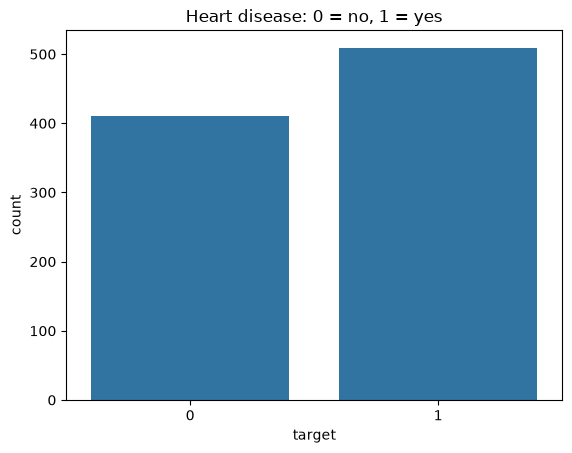

In [6]:
print(df["num"].value_counts().sort_index())
# I look at the original target: 0 = no disease, 1-4 = disease of increasing severity

df["target"] = (df["num"] > 0).astype(int)
# The brief asks me to predict IF a patient has heart disease, so I turn num into a yes/no target:
# 0 stays 0 (no disease), and 1, 2, 3, 4 all become 1 (disease is present)
print()
print(df["target"].value_counts())
print()
print(df["target"].value_counts(normalize=True).round(3))

sns.countplot(x="target", data=df)
plt.title("Heart disease: 0 = no, 1 = yes")
plt.show()

**Why I make the target binary:** the original `num` column goes from 0 to 4 (0 = no disease, 1–4 = disease of increasing severity). The brief asks me to predict *whether or not* a patient has heart disease, so I keep 0 as 0 and turn 1, 2, 3 and 4 into 1.

**What I see:** 509 patients (55.3%) have heart disease and 411 (44.7%) don't. The two classes are fairly balanced, so accuracy is a meaningful number here, but I still look at precision, recall and F1.

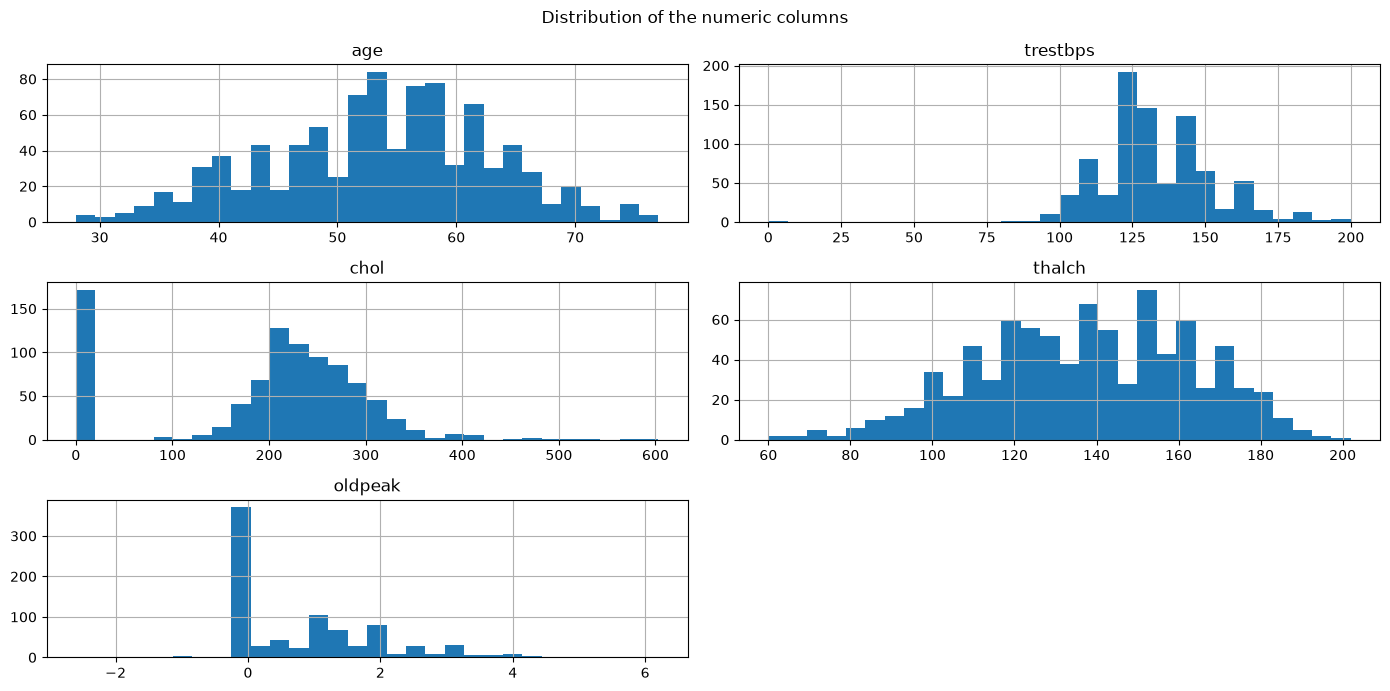

In [7]:
num_cols = ["age", "trestbps", "chol", "thalch", "oldpeak"]
# the continuous numeric columns
df[num_cols].hist(bins=30, figsize=(14, 7))
plt.suptitle("Distribution of the numeric columns")
plt.tight_layout()
plt.show()

**What I see:** `age`, `trestbps` and `thalch` look roughly bell-shaped. `oldpeak` is skewed to the right (most values near 0). `chol` has a clear spike at **0**, which confirms that 0 is used for missing cholesterol values.

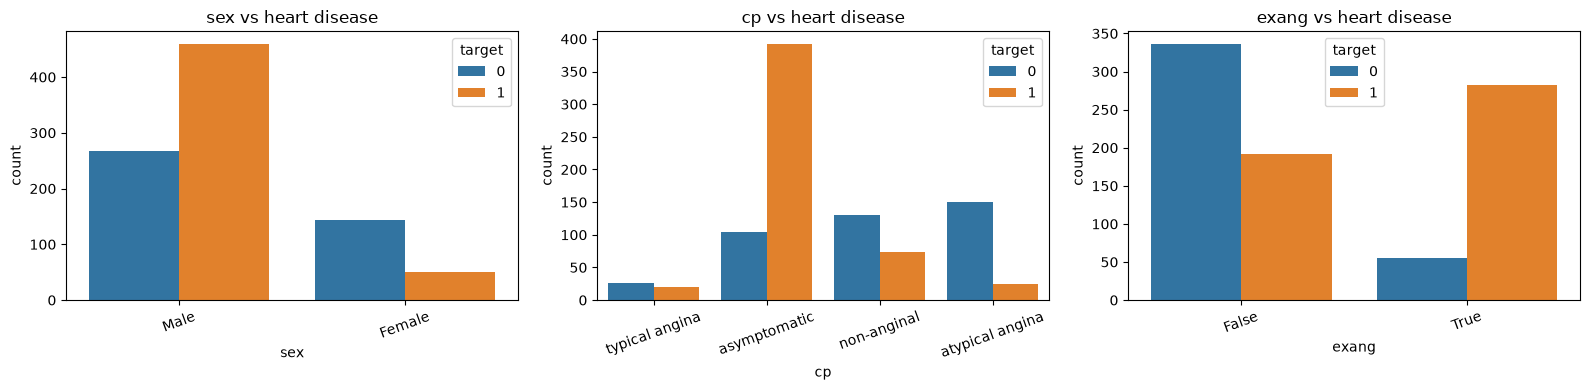

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["sex", "cp", "exang"]):
    sns.countplot(x=col, hue="target", data=df, ax=ax)
    ax.set_title(f"{col} vs heart disease")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()
# I compare how many patients with and without disease are in each group

**What I see:** in this data men have heart disease much more often than women (63% vs 26%). Patients with **asymptomatic** chest pain have disease in 79% of cases, while **atypical angina** has only 14%. Patients with chest pain during exercise (`exang` = True) have disease in 84% of cases, compared with 36% when it is False.

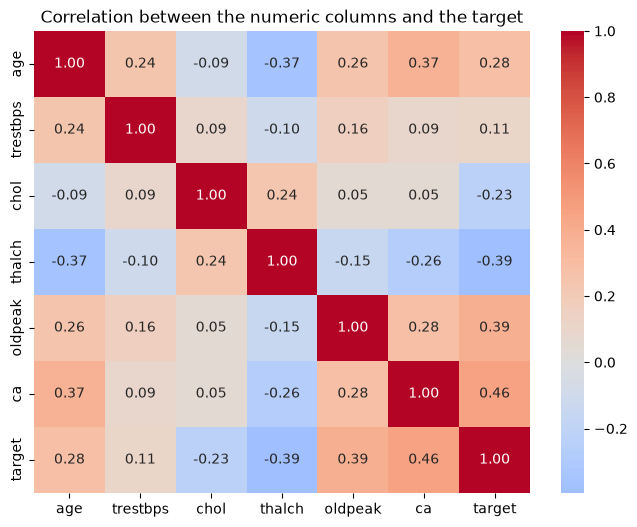

In [9]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols + ["ca", "target"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between the numeric columns and the target")
plt.show()

**What I see:** the strongest correlations with the target are `ca` (0.46), `oldpeak` (0.39) and `thalch` (-0.39: a lower maximum heart rate goes with more disease), then `age` (0.28). `chol` shows -0.23, which is strange (more cholesterol = less disease?). I think this comes from the 0 values: the Switzerland patients have `chol` = 0 and almost all of them have disease. This is one more reason to treat 0 as missing.

In [10]:
print(pd.crosstab(df["dataset"], df["target"], margins=True))
print()
print("Share of patients with disease in each hospital:")
print(df.groupby("dataset")["target"].mean().round(2))

target           0    1  All
dataset                     
Cleveland      165  139  304
Hungary        187  106  293
Switzerland      8  115  123
VA Long Beach   51  149  200
All            411  509  920

Share of patients with disease in each hospital:
dataset
Cleveland        0.46
Hungary          0.36
Switzerland      0.93
VA Long Beach    0.74
Name: target, dtype: float64


**What I see:** the share of patients with disease is very different between hospitals: 46% in Cleveland, 36% in Hungary, 74% in VA Long Beach and **93% in Switzerland**. That is why I will not use `dataset` as a feature: it is not a medical attribute, and the model could learn "which hospital" instead of "which symptoms".

### 1.3 Handle missing values

I check every column for missing values and I decide how to handle them.

In [11]:
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(1),
})
print(missing[missing["missing"] > 0].sort_values("missing", ascending=False))
# I count the empty values in every column

          missing  percent
ca            611     66.4
thal          486     52.8
slope         309     33.6
fbs            90      9.8
oldpeak        62      6.7
trestbps       59      6.4
exang          55      6.0
thalch         55      6.0
chol           30      3.3
restecg         2      0.2


**What I see:** `ca` is missing in 66.4% of the rows, `thal` in 52.8% and `slope` in 33.6%. The other columns are missing less than 10%.

In [12]:
print("chol equal to 0:", (df["chol"] == 0).sum())
print("trestbps equal to 0:", (df["trestbps"] == 0).sum())
print()
print("chol = 0 by hospital:")
print(df[df["chol"] == 0]["dataset"].value_counts())
# A cholesterol of 0 or a blood pressure of 0 is impossible for a living patient,
# so I check if 0 is used as a hidden "missing" value

chol equal to 0: 172
trestbps equal to 0: 1

chol = 0 by hospital:
dataset
Switzerland      123
VA Long Beach     49
Name: count, dtype: int64


**What I see:** 172 patients have `chol` = 0 (all 123 from Switzerland and 49 from VA Long Beach) and 1 patient has `trestbps` = 0. These are not real measurements, so I turn them into missing values.

In [13]:
df[["chol", "trestbps"]] = df[["chol", "trestbps"]].replace(0, np.nan)
# I turn the impossible 0 values into real missing values

X = df.drop(columns=["id", "dataset", "num", "target", "ca"])
y = df["target"]
# I drop:
# - id: just a row number, it says nothing about the patient
# - dataset: the hospital name, not a medical attribute (and the disease rate is very different per hospital, so the model could learn the hospital instead of the medicine)
# - num and target: these are the answer, keeping them would be cheating (leakage)
# - ca: about two thirds of the values are missing, so filling it would mostly be guessing
print("Features I keep:", list(X.columns))
print("X shape:", X.shape)
print()
print("Missing values left in X:")
print(X.isna().sum()[X.isna().sum() > 0])

Features I keep: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'thal']
X shape: (920, 12)

Missing values left in X:
trestbps     60
chol        202
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
thal        486
dtype: int64


**What I see:** I keep 12 medical features. After turning the zeros into missing values, `chol` now has 202 missing values. I will fill all the remaining missing values inside the pipeline.

**How I fill the missing values that are left:** numeric columns get the **median** of the training set, and categorical columns get a new category **"unknown"** (so I don't pretend I know the real value, for example for `thal` where about half is missing).

I don't fill them here on the whole dataset. I put the filling inside a scikit-learn **Pipeline** (below), so the median is learned **only from the training set** and the test set stays truly "unseen".

### 1.4 Encode categorical variables

I turn categorical columns into numbers so logistic regression can use them.

In [14]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

for col in ["fbs", "exang"]:
    X[col] = X[col].map({True: "yes", False: "no"})
# fbs and exang are True/False with some empty values; I turn them into text categories so they are encoded like the others

cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]
numeric_cols = ["age", "trestbps", "chol", "thalch", "oldpeak"]

categorical_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="unknown")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
# One-hot encoding makes one 0/1 column per category (for example cp_asymptomatic = 1 or 0),
# because logistic regression can only work with numbers

for col in cat_cols:
    print(col, "->", sorted(X[col].fillna("unknown").unique()))

sex -> ['Female', 'Male']
cp -> ['asymptomatic', 'atypical angina', 'non-anginal', 'typical angina']
fbs -> ['no', 'unknown', 'yes']
restecg -> ['lv hypertrophy', 'normal', 'st-t abnormality', 'unknown']
exang -> ['no', 'unknown', 'yes']
slope -> ['downsloping', 'flat', 'unknown', 'upsloping']
thal -> ['fixed defect', 'normal', 'reversable defect', 'unknown']


**What I see:** these are the categories each text column has. Every column with empty values now also gets an `unknown` category, and each category becomes its own 0/1 column after one-hot encoding.

### 1.5 Scale the features

I scale the features so they are on a comparable scale before I train the model.

In [15]:
numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
# StandardScaler puts every numeric column on the same scale (mean 0, standard deviation 1),
# so a big-number column like chol does not dominate a small one like oldpeak

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, cat_cols),
])
# The ColumnTransformer sends the numeric columns to the numeric pipeline and the categorical columns to the categorical pipeline
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## 2. Model Training

- Split the dataset into a training set and a testing set.
- Train a logistic regression model on the training set.

### 2.1 Train/test split

I split the dataset into a training set and a testing set.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
# 80% for training, 20% for testing.
# stratify=y keeps the same share of sick / healthy patients in both parts, random_state=42 makes it repeatable
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Share with disease - train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))

Train: (736, 12)  Test: (184, 12)
Share with disease - train: 0.553  test: 0.554


**What I see:** 736 patients are for training and 184 for testing. Thanks to `stratify`, the share with disease is almost the same in both (55.3% and 55.4%).

### 2.2 Train a logistic regression model

I train a logistic regression model on the training set.

In [17]:
from sklearn.model_selection import cross_val_score

model = Pipeline([
    ("preprocess", preprocessor),
    ("logreg", LogisticRegression(max_iter=1000)),
])
model.fit(X_train, y_train)
# fit() learns the medians, the scaling and the categories from the training set only, then trains the logistic regression

print("Number of features after encoding:", len(model.named_steps["preprocess"].get_feature_names_out()))

cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring="f1")
# I also check the model with 5-fold cross-validation on the training set, to see if the result is stable
print("5-fold CV F1 on the training set:", cv_scores.round(3))
print("Mean CV F1:", round(cv_scores.mean(), 3), "+/-", round(cv_scores.std(), 3))

Number of features after encoding: 28


5-fold CV F1 on the training set: [0.869 0.851 0.788 0.831 0.862]
Mean CV F1: 0.84 +/- 0.029


**What I see:** after encoding, the model works with 28 columns. The 5-fold cross-validation F1 on the training set is between 0.788 and 0.869, with a mean of **0.84**, so the model gives similar results on different parts of the data and does not depend on one lucky split.

## 3. Model Evaluation

- Evaluate the model on the testing set using accuracy, precision, recall, and F1 score.
- Use a confusion matrix to visualize the model’s performance.

### 3.1 Accuracy, precision, recall and F1 score

I evaluate the model on the testing set with accuracy, precision, recall, and the F1 score.

In [18]:
y_pred = model.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1 score :", round(f1_score(y_test, y_pred), 3))
# accuracy  = how many predictions are right overall
# precision = of the patients I flag as sick, how many really are sick
# recall    = of the patients who are really sick, how many I catch
# F1        = one number that balances precision and recall

Accuracy : 0.859
Precision: 0.865
Recall   : 0.882
F1 score : 0.874


**What I see on the test set:**
- **Accuracy 0.859**: about 86% of the 184 test patients are classified correctly.
- **Precision 0.865**: when the model says "disease", it is right about 87% of the time.
- **Recall 0.882**: the model finds about 88% of the patients who really have disease.
- **F1 0.874**: a good balance between precision and recall.

The test F1 (0.874) is close to the cross-validation F1 (0.84), so I don't see signs of overfitting.

### 3.2 Confusion matrix and classification report

I use a confusion matrix to visualize the model’s performance, and I print a classification report.

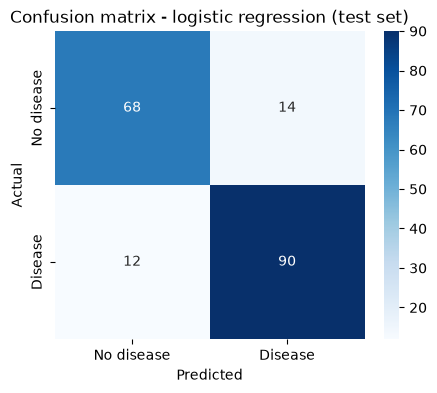

              precision    recall  f1-score   support

  No disease       0.85      0.83      0.84        82
     Disease       0.87      0.88      0.87       102

    accuracy                           0.86       184
   macro avg       0.86      0.86      0.86       184
weighted avg       0.86      0.86      0.86       184



In [19]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No disease", "Disease"], yticklabels=["No disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix - logistic regression (test set)")
plt.show()

print(classification_report(y_test, y_pred, target_names=["No disease", "Disease"]))

**What I see in the confusion matrix:** out of 102 sick patients in the test set, the model finds **90** and misses **12** (false negatives). Out of 82 healthy patients, it correctly says "no disease" for **68** and wrongly flags **14** (false positives). For a medical problem, the 12 missed sick patients are the most worrying mistake, because those people would not get further tests.

### 3.3 Visualizations

I add any other visualizations that helped me understand the dataset and the model’s performance.

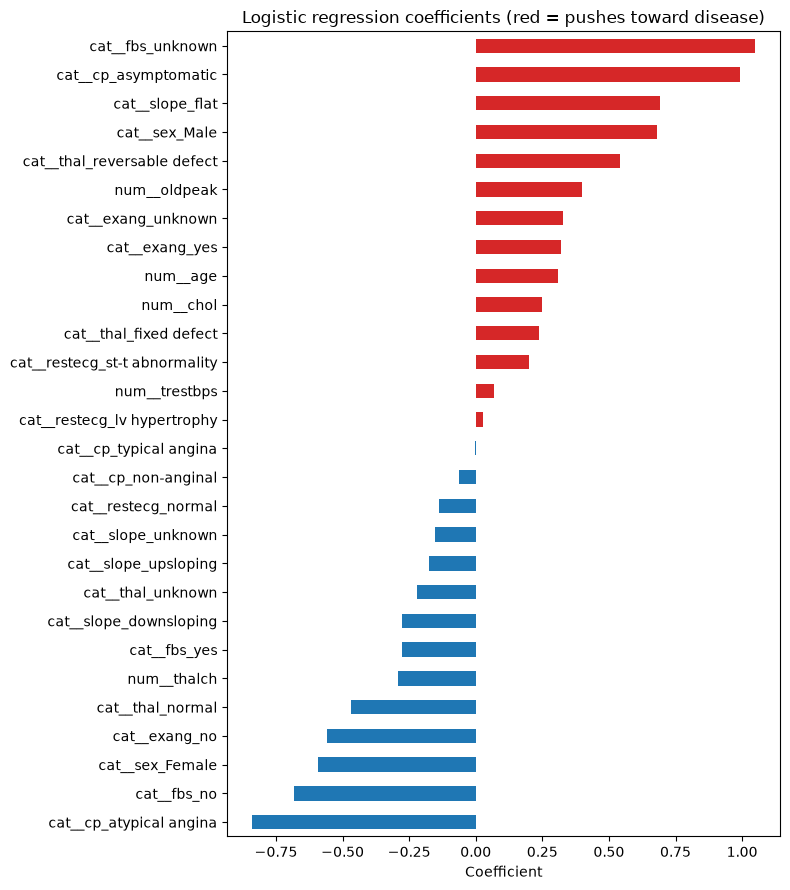

Top 5 toward disease:
cat__fbs_unknown               1.05
cat__cp_asymptomatic           0.99
cat__slope_flat                0.69
cat__sex_Male                  0.68
cat__thal_reversable defect    0.54
dtype: float64

Top 5 toward no disease:
cat__cp_atypical angina   -0.84
cat__fbs_no               -0.68
cat__sex_Female           -0.59
cat__exang_no             -0.56
cat__thal_normal          -0.47
dtype: float64


In [20]:
feature_names = model.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(model.named_steps["logreg"].coef_[0], index=feature_names).sort_values()

plt.figure(figsize=(8, 9))
coefs.plot(kind="barh", color=["tab:blue" if c < 0 else "tab:red" for c in coefs])
plt.title("Logistic regression coefficients (red = pushes toward disease)")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()
print("Top 5 toward disease:")
print(coefs.tail(5)[::-1].round(2))
print()
print("Top 5 toward no disease:")
print(coefs.head(5).round(2))

**What I see:** positive coefficients push the prediction toward disease and negative ones toward no disease. Chest pain type `asymptomatic`, a `flat` slope, being male and a `reversable defect` thal result push toward disease, and `atypical angina`, being female, `exang` = no and a `normal` thal push toward no disease. These match what I saw in the EDA.

One thing I need to be careful about: the biggest positive coefficient is `fbs_unknown` (fasting blood sugar is missing). Most of the missing `fbs` values come from the Switzerland hospital (75 of 90), where 93% of patients are sick. So the model partly learns "this value is missing" as a hint for the hospital, not something medical. It's a limitation of this combined dataset.

ROC AUC:

 0.914


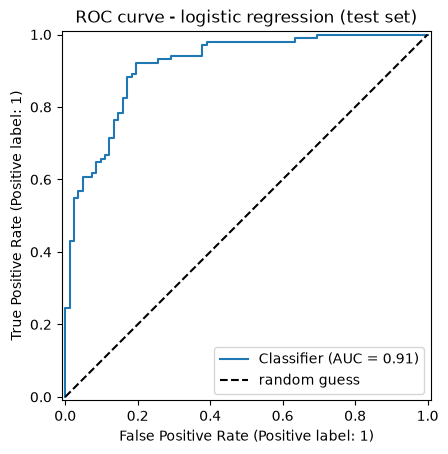

In [21]:
from sklearn.metrics import RocCurveDisplay, roc_auc_score

y_proba = model.predict_proba(X_test)[:, 1]
# the probability of disease that the model gives each test patient
print("ROC AUC:", round(roc_auc_score(y_test, y_proba), 3))
RocCurveDisplay.from_predictions(y_test, y_proba)
plt.plot([0, 1], [0, 1], "k--", label="random guess")
plt.title("ROC curve - logistic regression (test set)")
plt.legend()
plt.show()

**What I see:** the ROC AUC is **0.914**. This means that if I take one random sick patient and one random healthy patient, the model gives the sick one a higher probability about 91% of the time. The curve is well above the dashed "random guess" line.

## Conclusion

- I used the Heart Disease UCI dataset (920 patients from 4 hospitals) and turned the `num` column into a yes/no target: 55.3% of the patients have heart disease.
- In the EDA I found hidden missing values (`chol` = 0 for 172 patients, `trestbps` = 0 for 1 patient) and very incomplete columns (`ca` 66% missing, `thal` 53% missing). I dropped `id`, `dataset` and `ca`, filled numeric gaps with the training median and text gaps with an `unknown` category, one-hot encoded the categories and scaled the numeric features, all inside a Pipeline so the test set stays unseen.
- My logistic regression on the test set reached **accuracy 0.859, precision 0.865, recall 0.882 and F1 0.874**, with ROC AUC 0.914. The 5-fold cross-validation F1 (0.84) is close to that, so the result is stable.
- The model still misses 12 of the 102 sick test patients. To lower that in a real medical setting, I could lower the decision threshold to catch more sick patients (at the cost of more false alarms).
- A limitation: part of the signal comes from which values are missing (for example `fbs_unknown`), which is linked to the hospital the data came from, so I would want data from one consistent source before trusting the model in practice.